In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *
from functions.repeated_cv import *
from functions.postproc import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.ensemble import ComponentwiseGradientBoostingSurvivalAnalysis
from sksurv.linear_model import CoxnetSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../data/data_cox/data.csv")

diagnosis_variables = []

with open("../../data/data_cox/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/data_cox/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

continuous_features = feature_columns

# ['Age', 'Ki67 positive cells (%) at CB', 'N (Regional nodes affected) 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered']

In [3]:
# continuous_features = [col for col in continuous_features if col in feature_columns]

In [4]:
alpha_range = np.logspace(-4, -1, 10)
l1_ratio_range = [0.001, 0.01, 0.1, 0.5, 0.8, 1.0]

# alpha_range = [0.000615848, 0.000464159]
# l1_ratio_range = [0.1, 0.5, 0.8, 1.0]

n_controls = ["Full"]

metrics = ['c-index', 'int-brier-score', 'c-index-ipcw', 'r2-ibs','cumulative-dynamic-prauc', 'cumulative-dynamic-auc', 'log-loss', 'partial-likelihood']

In [7]:
# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

In [19]:
results_df, summary_df, best_params = subsampling_repeated_grid_search(
                                     subsampling, x_train, y_train, alpha_range, l1_ratio_range, 
                                     controls_per_case_range=n_controls, metrics=metrics, feature_columns=feature_columns,
                                     event_col='Regional LN recurrence', 
                                     time_col='Survival days',
                                     scale_data=True, scaler_type='standard',
                                     continuous_features=continuous_features,
                                     use_sample_weights=False, weight_ratio=None,
                                     n_splits=4, n_repeats=5, base_random_state=42,
                                     verbose=True)

SUBSAMPLING REPEATED GRID SEARCH
Controls per case: ['Full']
L1 ratios: [0.001, 0.01, 0.1, 0.5, 0.8, 1.0]
Alphas: 10 values from 1.00e-04 to 1.00e-01
Total hyperparameter combinations: 60
Folds per repetition: 4
Repetitions: 5
Total evaluations: 1200
Scaling: Yes (standard)
Sample weights: No

[1/60] controls=Full (no subsampling), l1=0.001, alpha=1.00e-04 (elapsed: 0.0min, est. remaining: 0.0min)
⚠️  Warning: Model fitting failed with error: Numerical error, because weights are too large. Consider increasing alpha.
⚠️  Warning: Model fitting failed with error: Numerical error, because weights are too large. Consider increasing alpha.
⚠️  Warning: Model fitting failed with error: Numerical error, because weights are too large. Consider increasing alpha.
⚠️  Warning: Model fitting failed with error: Numerical error, because weights are too large. Consider increasing alpha.
⚠️  Warning: Model fitting failed with error: Numerical error, because weights are too large. Consider increasing a

c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\metrics.py:498: RuntimeWarning: invalid value encountered in divide
  true_pos = cumsum_tp / cumsum_tp[-1]


⚠️  Warning: Brier score calculation failed: Input estimate contains NaN.
⚠️  Warning: R²_IBS calculation failed: Input estimate contains NaN.
⚠️  Warning: Log loss calculation failed: Input contains NaN.
⚠️  Warning: Brier score calculation failed: Input estimate contains NaN.
⚠️  Warning: R²_IBS calculation failed: Input estimate contains NaN.
⚠️  Warning: Log loss calculation failed: Input contains NaN.
⚠️  Warning: Model fitting failed with error: Numerical error, because weights are too large. Consider increasing alpha.
⚠️  Warning: Brier score calculation failed: Input estimate contains NaN.
⚠️  Warning: R²_IBS calculation failed: Input estimate contains NaN.
⚠️  Warning: Log loss calculation failed: Input contains NaN.


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\metrics.py:498: RuntimeWarning: invalid value encountered in divide
  true_pos = cumsum_tp / cumsum_tp[-1]


⚠️  Warning: Brier score calculation failed: Input estimate contains NaN.
⚠️  Warning: R²_IBS calculation failed: Input estimate contains NaN.
⚠️  Warning: Log loss calculation failed: Input contains NaN.
⚠️  Warning: Model fitting failed with error: Numerical error, because weights are too large. Consider increasing alpha.


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\metrics.py:498: RuntimeWarning: invalid value encountered in divide
  true_pos = cumsum_tp / cumsum_tp[-1]


... (159 outputs left out)

c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\metrics.py:498: RuntimeWarning: invalid value encountered in divide
  true_pos = cumsum_tp / cumsum_tp[-1]
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\metrics.py:498: RuntimeWarning: invalid value encountered in divide
  true_pos = cumsum_tp / cumsum_tp[-1]
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\metrics.py:498: RuntimeWarning: invalid value encountered in divide
  true_pos = cumsum_tp / cumsum_tp[-1]


[60/60] controls=Full (no subsampling), l1=1.000, alpha=1.00e-01 (elapsed: 95.9min, est. remaining: 0.0min)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\metrics.py:498: RuntimeWarning: invalid value encountered in divide
  true_pos = cumsum_tp / cumsum_tp[-1]
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\metrics.py:498: RuntimeWarning: invalid value encountered in divide
  true_pos = cumsum_tp / cumsum_tp[-1]
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\metrics.py:498: RuntimeWarning: invalid value encountered in divide
  true_pos = cumsum_tp / cumsum_tp[-1]
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)



REPEATED GRID SEARCH COMPLETE
Total time: 96.3 minutes

Best parameters for each metric:
--------------------------------------------------------------------------------

c-index:
  n_controls_per_case: Full (no subsampling)
  l1_ratio: 0.0010
  alpha: 4.6416e-03
  Score: 0.8573 ± 0.0483

int-brier-score:
  n_controls_per_case: Full (no subsampling)
  l1_ratio: 0.0010
  alpha: 4.6416e-03
  Score: 0.0088 ± 0.0009

c-index-ipcw:
  n_controls_per_case: Full (no subsampling)
  l1_ratio: 0.8000
  alpha: 1.0000e-04
  Score: 0.7187 ± 0.0883

r2-ibs:
  n_controls_per_case: Full (no subsampling)
  l1_ratio: 0.5000
  alpha: 1.0000e-04
  Score: 0.0492 ± 0.1740

cumulative-dynamic-prauc:
  n_controls_per_case: Full (no subsampling)
  l1_ratio: 0.5000
  alpha: 4.6416e-02
  Score: 0.5053 ± 0.0009

cumulative-dynamic-auc:
  n_controls_per_case: Full (no subsampling)
  l1_ratio: 0.1000
  alpha: 2.1544e-04
  Score: 0.8432 ± 0.0438

log-loss:
  n_controls_per_case: Full (no subsampling)
  l1_ratio: 0.0

In [20]:
cox_clean = clean_cox_data(summary_df)
cox_clean.to_csv('cox_standard.csv', index=False)

  Checked 20 c-index fold columns and 20 c-index-ipcw fold columns
  Removed 16 rows with missing fold values (60 -> 44)


In [19]:
np.sum(y_train['event'])

np.int64(29)

Using the model with the lowest brier socre

In [ ]:
# Patients with repeated PERSON_ID in the full dataset
repeated_ids = survival_dataset.loc[
    survival_dataset["PERSON_ID"].duplicated(keep=False), "PERSON_ID"
].unique()

repeated_patients = survival_dataset[
    survival_dataset["PERSON_ID"].isin(repeated_ids)
].copy().sort_values(["PERSON_ID", "Survival days"])

print(f"Number of repeated PERSON_IDs: {len(repeated_ids)}")
print(f"Number of rows with repeated PERSON_IDs: {len(repeated_patients)}")

repeated_patients

In [5]:
# Define time points for calibration analysis (1, 2, 3, 4, 5, 7, 10, 14 years(last event))
time_points = [365, 730, 1095, 1460, 1825, 2557, 3653, 5381]  # in days

# Use the best model parameters found earlier
best_params_for_calibration = {
    'alphas': [0.001],
    'l1_ratio': 0.01,
    'fit_baseline_model': True
    }

n_controls=["Full"]

In [16]:
# Collect predictions using repeated CV (same methodology as training)
predictions_df = collect_cv_predictions_for_calibration(
    model_class=CoxnetSurvivalAnalysis,
    X=x_train,
    y=y_train,
    model_params=best_params_for_calibration,
    time_points=time_points,
    scale_data=True,
    scaler_type='minmax', 
    continuous_features=continuous_features,
    random_state=None,
    n_jobs=-1,
    n_controls_per_case=None,  
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4,
    n_repeats=1, 
    base_random_state=42,
    recalibrate=False,
    recalibration_type='beta',
    verbose=True
)

# Save predictions for later analysis
predictions_df.to_csv('cox_calibration_predictions.csv', index=False)
print(f"\nPredictions saved to 'cox_calibration_predictions.csv'")

Time points: [365, 730, 1095, 1460, 1825, 2557, 3653, 5381]
CV: 1 repeats x 4 folds = 4 models

Repeat 1/1
  Fold 1/4... Creating model with params: {'alphas': [0.001], 'l1_ratio': 0.01, 'fit_baseline_model': True}
Done
  Fold 2/4... Creating model with params: {'alphas': [0.001], 'l1_ratio': 0.01, 'fit_baseline_model': True}
Done
  Fold 3/4... Creating model with params: {'alphas': [0.001], 'l1_ratio': 0.01, 'fit_baseline_model': True}
Done
  Fold 4/4... Creating model with params: {'alphas': [0.001], 'l1_ratio': 0.01, 'fit_baseline_model': True}
Done

Total predictions collected: 2584
Unique samples: 2584

Predictions saved to 'cox_calibration_predictions.csv'


Jittered risk score plot saved to cox_actually_min_risk_score_distribution.png

Time point 365 days:
  Events: 4, No events: 2580
  Mean survival prob (event): 0.996
  Mean survival prob (no event): 0.998
  Cohen's d: 0.96

Time point 730 days:
  Events: 9, No events: 2575
  Mean survival prob (event): 0.981
  Mean survival prob (no event): 0.996
  Cohen's d: 0.76

Time point 1095 days:
  Events: 14, No events: 2570
  Mean survival prob (event): 0.959
  Mean survival prob (no event): 0.993
  Cohen's d: 0.83

Time point 1460 days:
  Events: 18, No events: 2566
  Mean survival prob (event): 0.938
  Mean survival prob (no event): 0.990
  Cohen's d: 0.90

Time point 1825 days:
  Events: 24, No events: 2560
  Mean survival prob (event): 0.916
  Mean survival prob (no event): 0.984
  Cohen's d: 0.79

Time point 2557 days:
  Events: 26, No events: 2558
  Mean survival prob (event): 0.906
  Mean survival prob (no event): 0.980
  Cohen's d: 0.75

Time point 3653 days:
  Events: 27, No events: 2

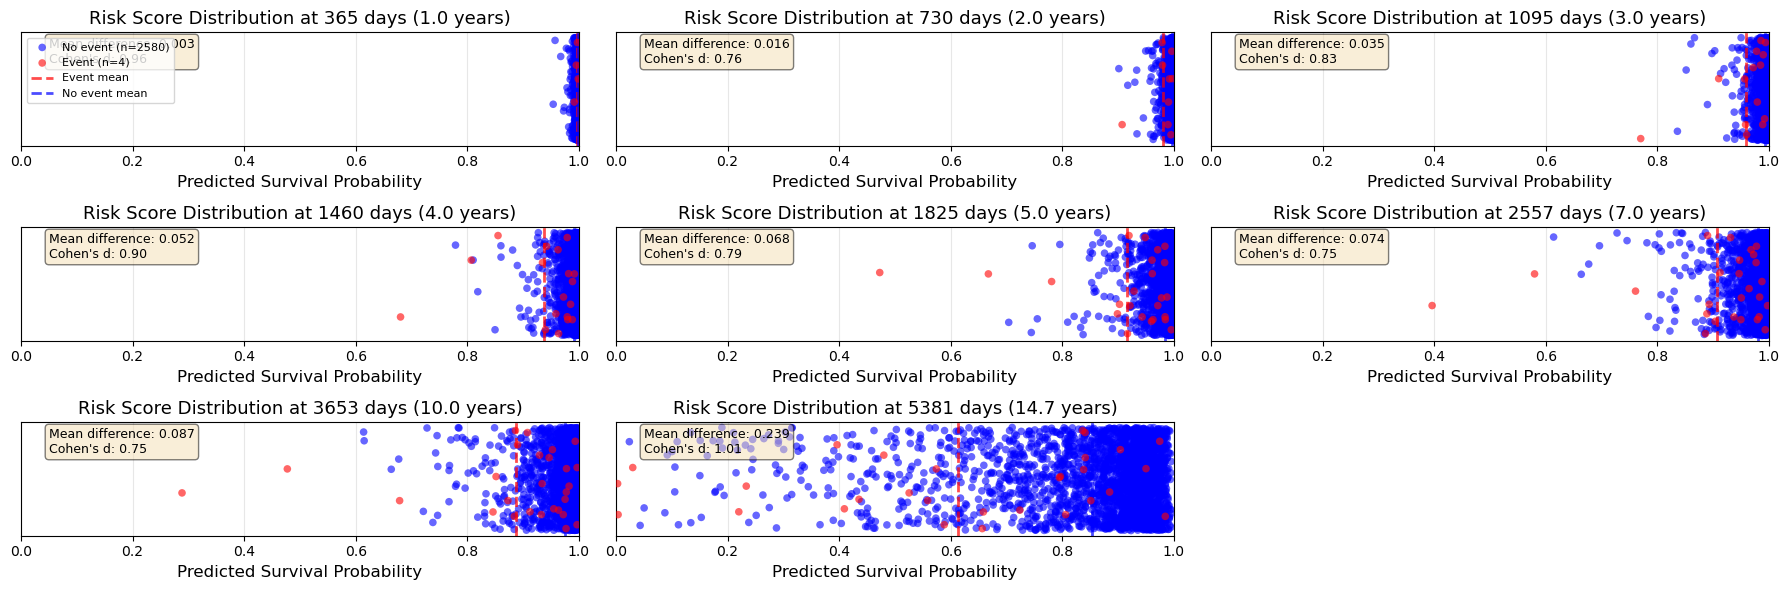

In [17]:
# Basic usage
fig, axes, stats = plot_jittered_risk_scores(
    predictions_df=predictions_df,
    time_points=time_points,
    figsize=(18, 6),
    save_path='cox_actually_min_risk_score_distribution.png'
)  

# Check separation statistics
for t, stat in stats.items():
    print(f"\nTime point {t} days:")
    print(f"  Events: {stat['n_events']}, No events: {stat['n_no_events']}")
    print(f"  Mean survival prob (event): {stat['event_mean']:.3f}")
    print(f"  Mean survival prob (no event): {stat['no_event_mean']:.3f}")
    print(f"  Cohen's d: {stat['cohens_d']:.2f}")

In [352]:
# Calculate Brier Score at each time point
brier_scores = {}

for t in time_points:
    col_name = f'pred_surv_{int(t)}d'
    
    # Get predictions and actual outcomes
    df_temp = predictions_df[['sample_idx', 'event', 'time', col_name]].dropna()
    
    # Calculate observed outcome at this time point
    # 1 if survived past time point, 0 if had event before/at time point
    observed = ((df_temp['time'] > t) | 
                ((df_temp['time'] <= t) & (df_temp['event'] == 0))).astype(int)
    
    predicted = df_temp[col_name].values
    
    # Brier Score: mean squared error between predicted and observed
    brier = np.mean((predicted - observed) ** 2)
    
    brier_scores[t] = brier
    print(f"Time point {t} days ({t/365:.1f} years): Brier Score = {brier:.4f}")

# Store in a DataFrame for easy viewing
brier_scores_df = pd.DataFrame([
    {'time_point_days': t, 'time_point_years': t/365, 'brier_score': score}
    for t, score in brier_scores.items()
])

print("\nBrier Scores Summary:")
print(brier_scores_df.to_string(index=False))

Time point 365 days (1.0 years): Brier Score = 0.0012
Time point 730 days (2.0 years): Brier Score = 0.0032
Time point 1095 days (3.0 years): Brier Score = 0.0045
Time point 1460 days (4.0 years): Brier Score = 0.0064
Time point 1825 days (5.0 years): Brier Score = 0.0084

Brier Scores Summary:
 time_point_days  time_point_years  brier_score
             365               1.0     0.001155
             730               2.0     0.003198
            1095               3.0     0.004453
            1460               4.0     0.006421
            1825               5.0     0.008447


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis_2\functions\postproc.py:636: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


Calibration plot saved to cox_actually_calibration_curves.png


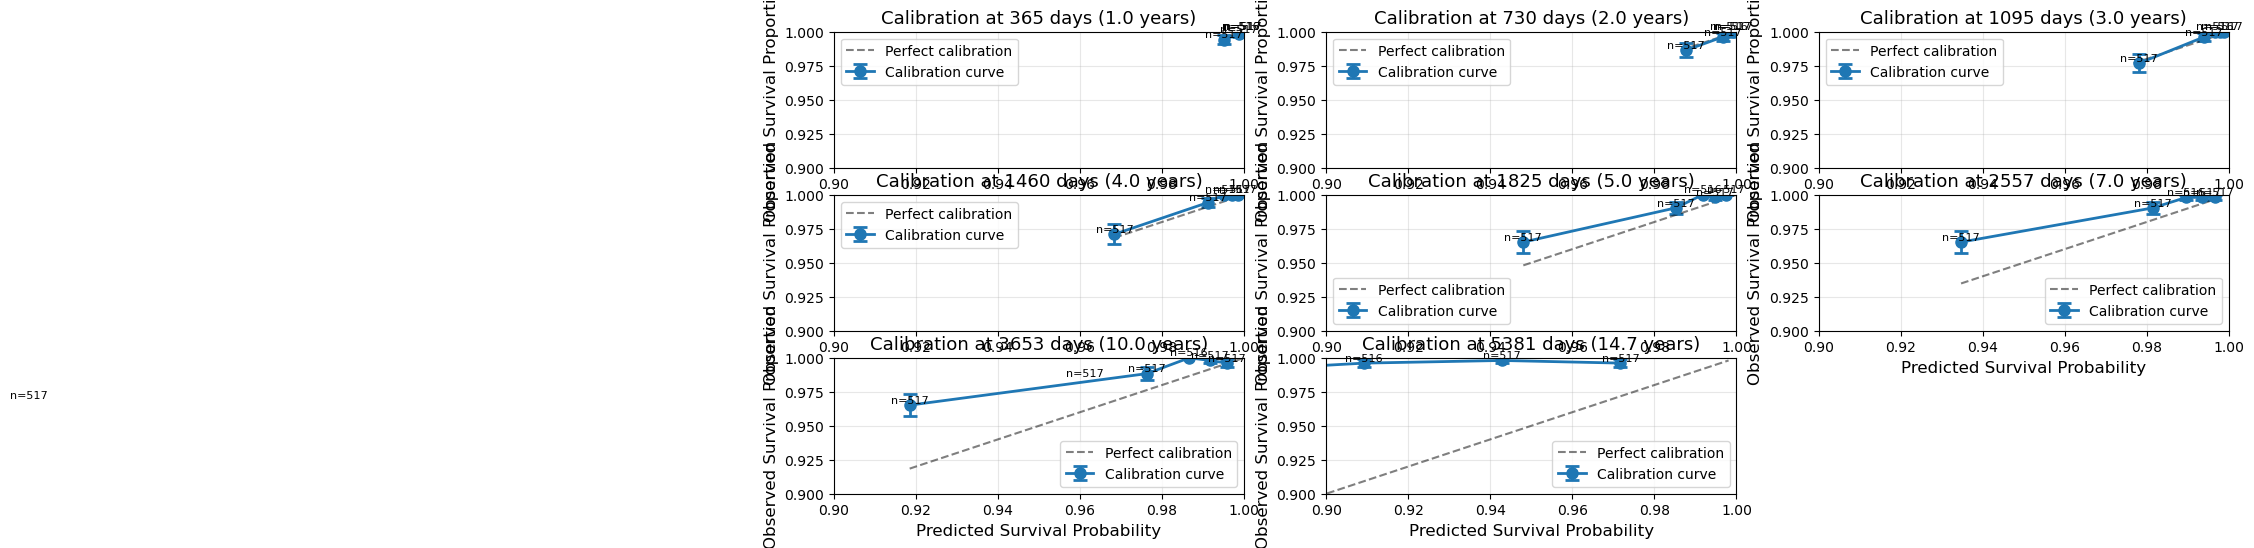

In [18]:
# Generate calibration curves for all time points
fig, axes, calibration_results = plot_calibration_curves(
    predictions_df=predictions_df,
    time_points=time_points,
    n_bins=5,
    strategy='quantile',  # Equal-sized bins based on prediction quantiles
    figsize=(18, 6),
    save_path='cox_actually_calibration_curves.png',
    xlim=(0.9, 1),
    ylim=(0.9, 1),
    error_bar_type='se'
)

plt.show()

In [27]:
survival_dataset[survival_dataset['PERSON_ID'] == 513]

,PERSON_ID,Regional LN recurrence,Survival days,Adjuvant therapy using biological drugs,Trastuzumab or other drugs,Radiotherapy (RT) performed,Radiotherapy on chest wall,Radiotherapy on supraclavicular area,Radiotherapy on internal mammary chain,Endocrine therapy performed,...,Classification with respect to other lesions_3.0,Isotype at CB_1.0,Isotype at CB_2.0,Isotype at CB_3.0,Isotype at CB_4.0,Disease extent_1.0,Disease extent_2.0,pT_pT2,pT_pT3_4,pT_pTIs
493,513,0.0,2086.0,0,0.0,1,1.0,0.0,0.0,0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
494,513,0.0,2227.0,0,0.0,1,1.0,0.0,0.0,0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


  Processing fold 1/4...
  Processing fold 2/4...
  Processing fold 3/4...
  Processing fold 4/4...

  Collected survival curves for 2584 patients


(<Figure size 1500x1000 with 1 Axes>,
 <Axes: title={'center': 'Individual Patient Survival Curves (CV Predictions)'}, xlabel='Time (days)', ylabel='Predicted Survival Probability'>,
     patient_idx  event    time event_status  n_predictions
 0             5   True  4103.0        Event              1
 1           330   True  2648.0        Event              1
 2           531   True  1799.0        Event              1
 3           648   True  1784.0        Event              1
 4           649   True  1762.0        Event              1
 5           690   True  1543.0        Event              1
 6           741   True  1306.0        Event              1
 7           973   True   278.0        Event              1
 8          1021   True   799.0        Event              1
 9          1049   True   986.0        Event              1
 10         1135   True   192.0        Event              1
 11         1192   True   994.0        Event              1
 12         1244   True  1695.0      

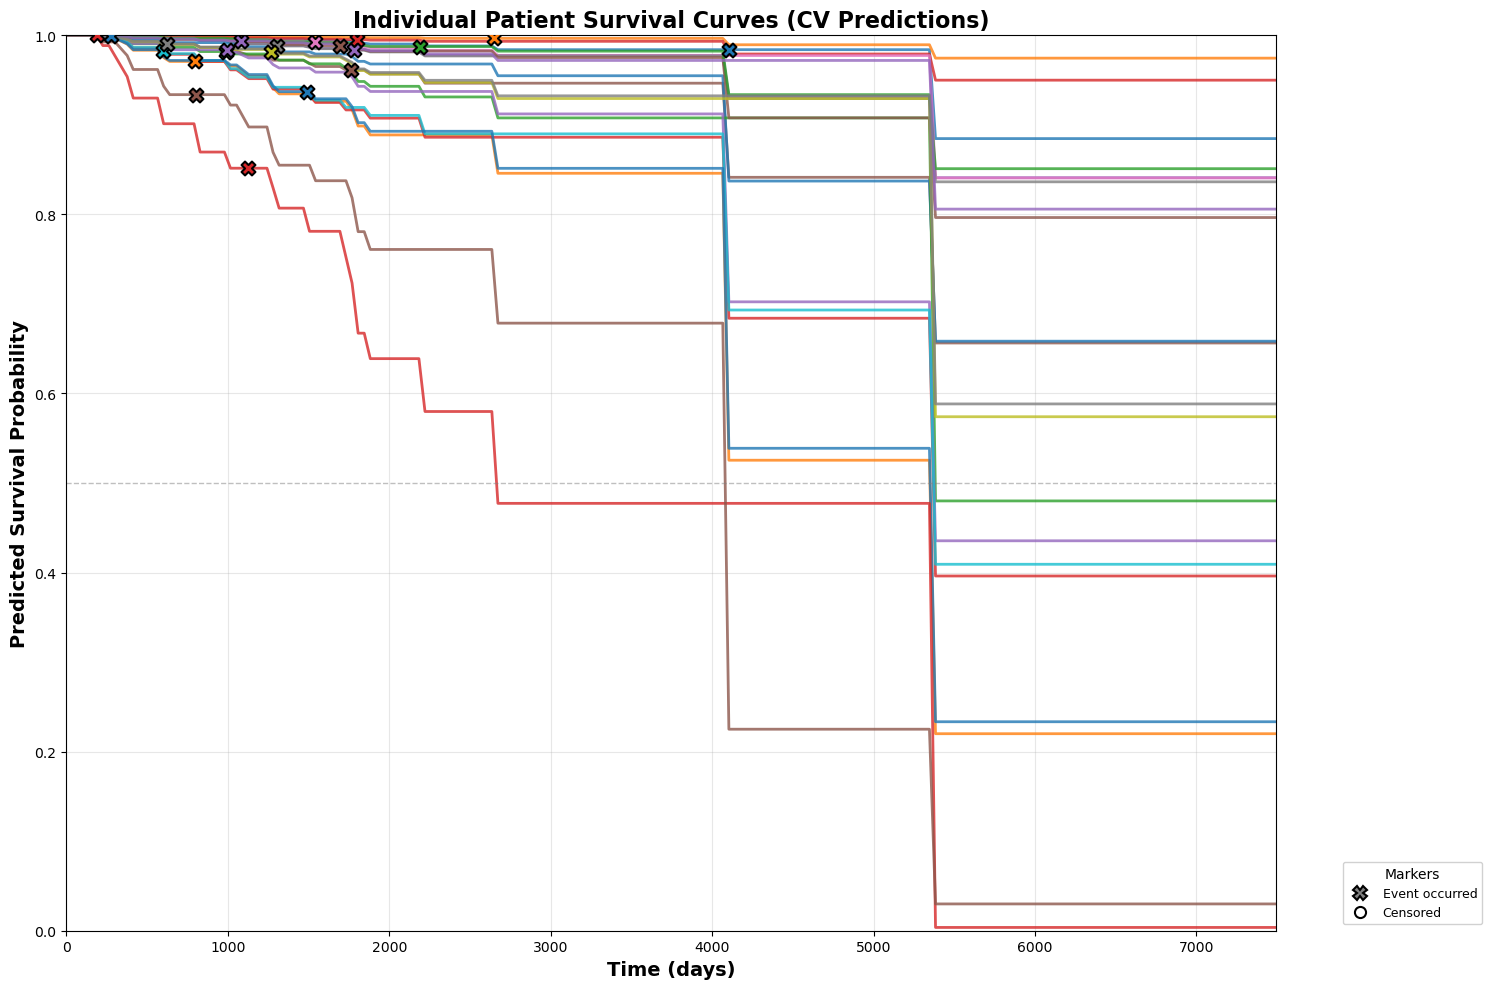

In [20]:
plot_individual_survival_curves(model_class=CoxnetSurvivalAnalysis, X=x_train, y=y_train, model_params=best_params_for_calibration,
                                    patient_indices=None, 
                                    n_patients=29, select_events_only=True,
                                    scale_data=True, scaler_type='minmax',
                                    continuous_features=continuous_features,
                                    n_controls_per_case=None, dataset=None,
                                    feature_columns=None,
                                    event_col='Regional LN recurrence',
                                    time_col='Survival days',
                                    n_splits=4, n_repeats=1, random_state=42,
                                    time_range=None, n_time_points=200,
                                    figsize=(15, 10), save_path=None,
                                    show_event_markers=True, show_censoring_markers=True,
                                    event_marker_size=100, censoring_marker_size=80,
                                    colormap='tab10', alpha=0.8,
                                    show_legend=True, legend_outside=True,
                                    show_confidence_interval=False, ci_alpha=0.2,
                                    compute_weights=False,
                                    verbose=True)

  Processing fold 1/4...
  Processing fold 2/4...
  Processing fold 3/4...
  Processing fold 4/4...

  Collected survival curves for 2584 patients


(<Figure size 1500x1000 with 1 Axes>,
 <Axes: title={'center': 'Individual Patient Survival Curves (CV Predictions)'}, xlabel='Time (days)', ylabel='Predicted Survival Probability'>,
      patient_idx  event    time event_status  n_predictions
 0           2099  False   789.0     Censored              1
 1            435  False  1775.0     Censored              1
 2           1729  False  1163.0     Censored              1
 3            321  False  1826.0     Censored              1
 4           2582  False   298.0     Censored              1
 ..           ...    ...     ...          ...            ...
 495          438  False  1826.0     Censored              1
 496          480  False   572.0     Censored              1
 497          457  False  1826.0     Censored              1
 498          163  False  1826.0     Censored              1
 499          402  False  1826.0     Censored              1
 
 [500 rows x 5 columns],
 {np.int32(2099): {'time_points': array([   0.        ,   

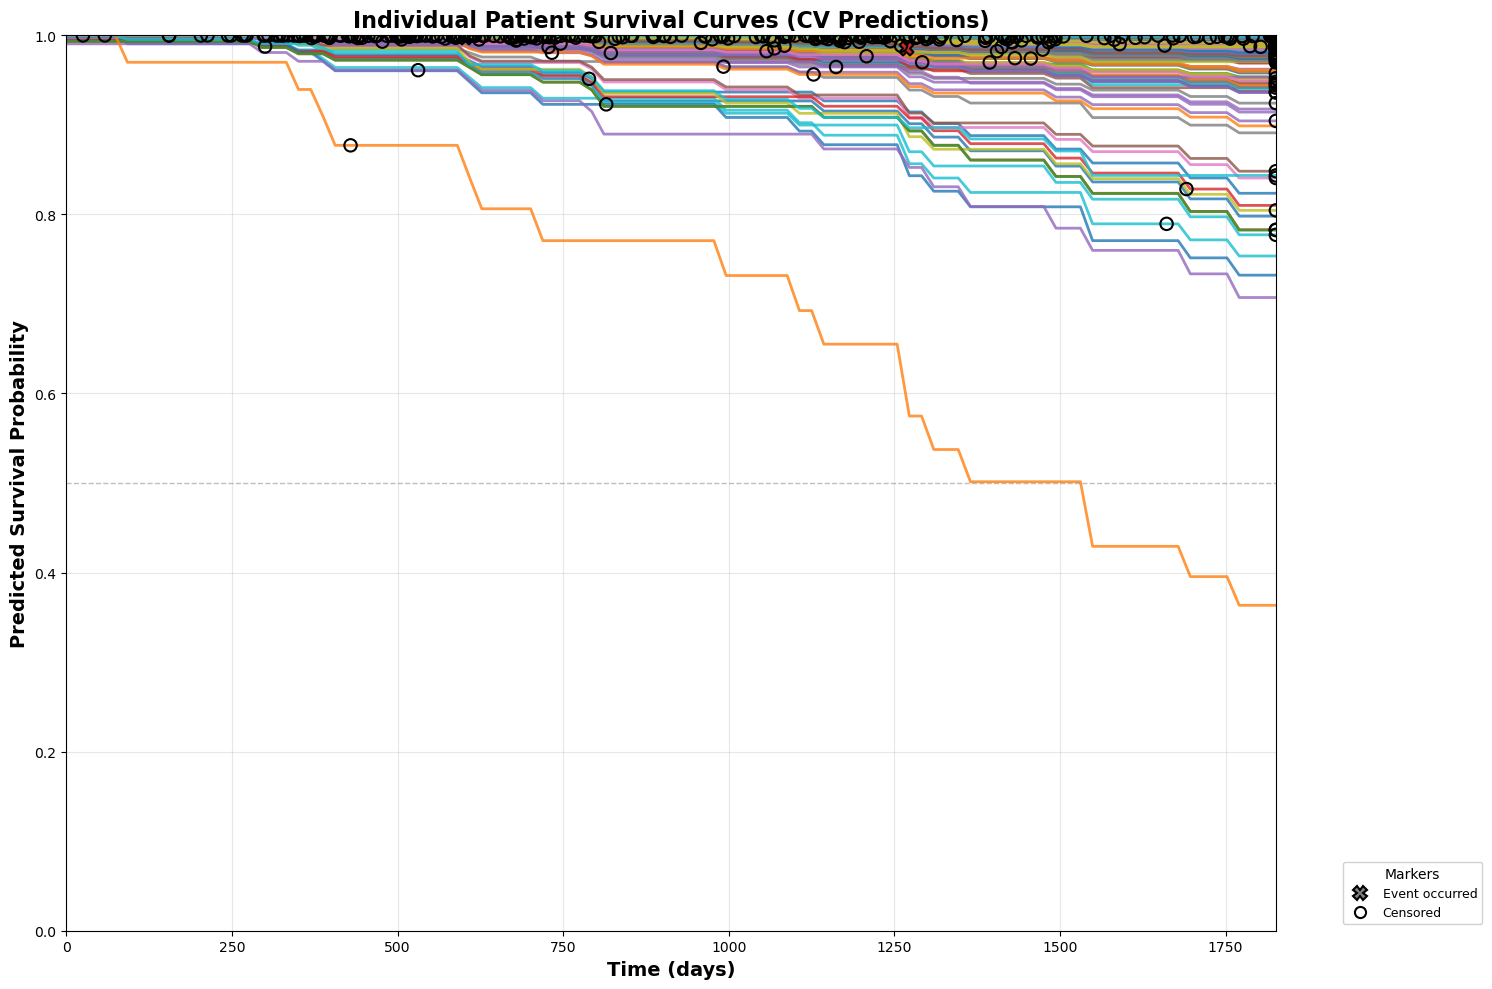

In [148]:
plot_individual_survival_curves(model_class=CoxnetSurvivalAnalysis, X=x_train, y=y_train, model_params=best_params_for_calibration,
                                    patient_indices=None, 
                                    n_patients=500, select_events_only=False,
                                    scale_data=True, scaler_type='minmax',
                                    continuous_features=continuous_features,
                                    n_controls_per_case=None, dataset=None,
                                    feature_columns=None,
                                    event_col='Regional LN recurrence',
                                    time_col='Survival days',
                                    n_splits=4, n_repeats=1, random_state=42,
                                    time_range=None, n_time_points=100,
                                    figsize=(15, 10), save_path=None,
                                    show_event_markers=True, show_censoring_markers=True,
                                    event_marker_size=100, censoring_marker_size=80,
                                    colormap='tab10', alpha=0.8,
                                    show_legend=True, legend_outside=True,
                                    show_confidence_interval=False, ci_alpha=0.2,
                                    compute_weights=False,
                                    verbose=True)

## Individual Survival Curves with 95% Confidence Intervals
The plot now includes 95% confidence intervals calculated from multiple CV repetitions

In [ ]:
# Example: Plot with 95% confidence intervals (requires n_repeats > 1)
# Set n_repeats=5 or higher for stable confidence intervals
# This will train 5 repeats x 12 folds = 60 models total
fig, ax, patient_info, surv_curves = plot_individual_survival_curves(
    model_class=CoxnetSurvivalAnalysis, 
    X=x_train, 
    y=y_train, 
    model_params=best_params_for_calibration,
    patient_indices=None, 
    n_patients=10, 
    select_events_only=True,
    scale_data=True, 
    scaler_type='minmax',
    continuous_features=continuous_features,
    n_splits=12, 
    n_repeats=5,  # Multiple repeats for confidence intervals
    random_state=42,
    time_range=None, 
    n_time_points=100,
    figsize=(15, 10), 
    save_path='survival_curves_with_ci.png',
    show_event_markers=True, 
    show_censoring_markers=True,
    event_marker_size=100, 
    censoring_marker_size=80,
    colormap='tab10', 
    alpha=0.8,
    show_legend=True, 
    legend_outside=True,
    show_confidence_interval=True,  # Enable 95% CI
    ci_alpha=0.2,  # CI band transparency
    verbose=True
)

print("\nPatient information:")
print(patient_info)

In [ ]:
# Alternative: Faster version without CI (single CV run, n_repeats=1)
# This is much faster but doesn't show uncertainty bands
fig, ax, patient_info, surv_curves = plot_individual_survival_curves(
    model_class=CoxnetSurvivalAnalysis, 
    X=x_train, 
    y=y_train, 
    model_params=best_params_for_calibration,
    patient_indices=None, 
    n_patients=10, 
    select_events_only=True,
    scale_data=True, 
    scaler_type='minmax',
    continuous_features=continuous_features,
    n_splits=12, 
    n_repeats=1,  # Single repetition (faster, no CI)
    random_state=42,
    show_confidence_interval=False,  # No CI
    verbose=True
)

## Predicting New Patients with Confidence Intervals

For a finalized model predicting on **new patients**, use bootstrap to get confidence intervals.
This trains multiple models on bootstrap samples of training data.

In [ ]:
# Example: Predict on new patients with bootstrap confidence intervals
# This simulates having new patients after your model is finalized

# For demonstration, we'll use test set as "new patients"
# In practice, replace x_test with your actual new patient data

# Get predictions with confidence intervals using bootstrap
predictions_df, all_bootstrap_preds = predict_new_patient_with_ci(
    model_class=CoxnetSurvivalAnalysis,
    X_train=x_train,
    y_train=y_train,
    X_new=x_test,  # Replace with your new patients
    model_params=best_params_for_calibration,
    time_points=time_points,  # [365, 730, 1095, 1460, 1825]
    n_bootstrap=100,  # Number of bootstrap samples (higher = more stable CI)
    scale_data=True,
    scaler_type='minmax',
    continuous_features=continuous_features,
    sample_weight=None,
    random_state=42,
    confidence_level=0.95,  # 95% confidence intervals
    verbose=True
)

print("\nPredictions summary:")
print(predictions_df.head(20))

# Show statistics for first patient at 5 years
patient_0_5y = predictions_df[(predictions_df['patient_idx'] == 0) & (predictions_df['time_point'] == 1825)]
print(f"\nPatient 0 at 5 years (1825 days):")
print(f"  Mean survival probability: {patient_0_5y['mean_surv_prob'].values[0]:.3f}")
print(f"  95% CI: [{patient_0_5y['lower_ci'].values[0]:.3f}, {patient_0_5y['upper_ci'].values[0]:.3f}]")
print(f"  Standard deviation: {patient_0_5y['std_surv_prob'].values[0]:.3f}")

In [ ]:
# Visualize predictions with confidence intervals
# Plot first 10 test patients

fig, ax = plot_new_patient_predictions_with_ci(
    predictions_df=predictions_df,
    all_predictions=all_bootstrap_preds,
    patient_indices=list(range(10)),  # Plot first 10 patients
    figsize=(15, 10),
    colormap='tab10',
    alpha=0.8,
    ci_alpha=0.2,
    show_individual_bootstraps=False,  # Set True to see all bootstrap curves (can be messy)
    bootstrap_alpha=0.05,
    save_path='new_patient_predictions_bootstrap_ci.png',
    show_legend=True,
    legend_outside=True
)

plt.show()

In [ ]:
# Analyze confidence interval widths (uncertainty)
# Wider intervals = more uncertainty in predictions

predictions_df['ci_width'] = predictions_df['upper_ci'] - predictions_df['lower_ci']

# Group by patient and calculate average CI width
ci_summary = predictions_df.groupby('patient_idx').agg({
    'ci_width': 'mean',
    'std_surv_prob': 'mean',
    'mean_surv_prob': 'mean'
}).reset_index()

ci_summary.columns = ['patient_idx', 'avg_ci_width', 'avg_std', 'avg_surv_prob']
ci_summary = ci_summary.sort_values('avg_ci_width', ascending=False)

print("Patients with highest prediction uncertainty (widest confidence intervals):")
print(ci_summary.head(10).to_string(index=False))

print("\n\nPatients with lowest prediction uncertainty (narrowest confidence intervals):")
print(ci_summary.tail(10).to_string(index=False))

# Visualize CI width distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histogram of CI widths
axes[0].hist(ci_summary['avg_ci_width'], bins=20, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Average CI Width', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Patients', fontsize=12, fontweight='bold')
axes[0].set_title('Distribution of Prediction Uncertainty', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Scatter: predicted survival vs uncertainty
axes[1].scatter(ci_summary['avg_surv_prob'], ci_summary['avg_ci_width'], 
               alpha=0.6, s=50, edgecolors='black', linewidth=0.5)
axes[1].set_xlabel('Average Predicted Survival Probability', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Average CI Width (Uncertainty)', fontsize=12, fontweight='bold')
axes[1].set_title('Prediction vs Uncertainty', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('prediction_uncertainty_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Analysis complete!")

### Summary: Two Approaches for Confidence Intervals

**1. Cross-Validation CI (for training data)**
- Function: `plot_individual_survival_curves()` with `n_repeats > 1`
- Use when: Analyzing model performance on training/validation data
- Method: Repeated CV - trains models on different train/val splits
- Provides: Out-of-sample predictions for all training data
- Interpretation: Shows model stability and prediction uncertainty from CV splits

**2. Bootstrap CI (for new patients)**
- Function: `predict_new_patient_with_ci()`
- Use when: Predicting on completely new patients (production/deployment)
- Method: Bootstrap - trains models on resampled training data
- Provides: Predictions with confidence intervals for new data
- Interpretation: Shows prediction uncertainty due to training data variability

**Key Differences:**
- CV is for **model validation** (how well does the model perform?)
- Bootstrap is for **new predictions** (how confident are we about this patient's survival?)
- Both quantify uncertainty, but from different sources

# Misclassification Analysis
Extract and analyze false negatives and false positives to understand prediction errors

In [27]:
def extract_misclassifications(predictions_df, time_points, threshold=0.5, use_median=False):
    """
    Extract false negatives and false positives at each time point.
    
    Parameters:
    -----------
    predictions_df : DataFrame
        DataFrame with predictions containing columns: sample_idx, event, time, pred_surv_*d
    time_points : list
        List of time points to analyze
    threshold : float
        Survival probability threshold for classification (default 0.5)
    use_median : bool
        If True, use median prediction as threshold instead of fixed value
    
    Returns:
    --------
    misclass_dict : dict
        Dictionary with misclassification info for each time point
    """
    misclass_dict = {}
    
    for t in time_points:
        col_name = f'pred_surv_{int(t)}d'
        
        # Get predictions and actual outcomes
        df_temp = predictions_df[['sample_idx', 'event', 'time', col_name]].dropna().copy()
        
        # Define actual outcome at this time point
        # Had event = 1 if event occurred at or before time point
        # No event = 0 if survived past time point OR censored after time point
        df_temp['had_event_by_t'] = ((df_temp['time'] <= t) & (df_temp['event'] == 1)).astype(int)
        df_temp['survived_past_t'] = ((df_temp['time'] > t) | 
                                       ((df_temp['time'] <= t) & (df_temp['event'] == 0))).astype(int)
        
        # Determine threshold
        if use_median:
            thresh = df_temp[col_name].median()
        else:
            thresh = threshold
        
        # Predicted outcome: 1 = predicted to survive (high surv prob), 0 = predicted to have event (low surv prob)
        df_temp['pred_survive'] = (df_temp[col_name] >= thresh).astype(int)
        
        # Classify predictions
        # True Positive (TP): Predicted survive AND actually survived
        df_temp['TP'] = (df_temp['pred_survive'] == 1) & (df_temp['survived_past_t'] == 1)
        
        # True Negative (TN): Predicted event AND actually had event
        df_temp['TN'] = (df_temp['pred_survive'] == 0) & (df_temp['had_event_by_t'] == 1)
        
        # False Positive (FP): Predicted survive BUT actually had event
        df_temp['FP'] = (df_temp['pred_survive'] == 1) & (df_temp['had_event_by_t'] == 1)
        
        # False Negative (FN): Predicted event BUT actually survived
        df_temp['FN'] = (df_temp['pred_survive'] == 0) & (df_temp['survived_past_t'] == 1)
        
        # Extract indices
        fn_indices = df_temp[df_temp['FN']]['sample_idx'].values
        fp_indices = df_temp[df_temp['FP']]['sample_idx'].values
        tp_indices = df_temp[df_temp['TP']]['sample_idx'].values
        tn_indices = df_temp[df_temp['TN']]['sample_idx'].values
        
        # Calculate metrics
        n_fn = len(fn_indices)
        n_fp = len(fp_indices)
        n_tp = len(tp_indices)
        n_tn = len(tn_indices)
        
        total = n_fn + n_fp + n_tp + n_tn
        accuracy = (n_tp + n_tn) / total if total > 0 else 0
        
        # Sensitivity (recall): TP / (TP + FN) - ability to predict survival
        sensitivity = n_tp / (n_tp + n_fn) if (n_tp + n_fn) > 0 else 0
        
        # Specificity: TN / (TN + FP) - ability to predict events
        specificity = n_tn / (n_tn + n_fp) if (n_tn + n_fp) > 0 else 0
        
        # Precision: TP / (TP + FP)
        precision = n_tp / (n_tp + n_fp) if (n_tp + n_fp) > 0 else 0
        
        misclass_dict[t] = {
            'threshold': thresh,
            'df': df_temp,
            'FN_indices': fn_indices,
            'FP_indices': fp_indices,
            'TP_indices': tp_indices,
            'TN_indices': tn_indices,
            'n_FN': n_fn,
            'n_FP': n_fp,
            'n_TP': n_tp,
            'n_TN': n_tn,
            'accuracy': accuracy,
            'sensitivity': sensitivity,
            'specificity': specificity,
            'precision': precision,
            'total_events': df_temp['had_event_by_t'].sum(),
            'total_survived': df_temp['survived_past_t'].sum()
        }
    
    return misclass_dict

In [28]:
# Extract misclassifications using median as threshold (more balanced)
misclass_results = extract_misclassifications(predictions_df, time_points, use_median=True)

# Print summary for each time point
print("=" * 80)
print("MISCLASSIFICATION SUMMARY")
print("=" * 80)

summary_data = []
for t in time_points:
    result = misclass_results[t]
    years = t / 365
    
    print(f"\n--- Time Point: {t} days ({years:.1f} years) ---")
    print(f"Threshold (median): {result['threshold']:.4f}")
    print(f"\nConfusion Matrix:")
    print(f"  Total Events by t:    {result['total_events']}")
    print(f"  Total Survived past t: {result['total_survived']}")
    print(f"\n  True Positives (predicted & survived):  {result['n_TP']}")
    print(f"  True Negatives (predicted & had event): {result['n_TN']}")
    print(f"  False Positives (predicted survive, had event): {result['n_FP']} ⚠️")
    print(f"  False Negatives (predicted event, survived):    {result['n_FN']} ⚠️")
    print(f"\nMetrics:")
    print(f"  Accuracy:    {result['accuracy']:.3f}")
    print(f"  Sensitivity: {result['sensitivity']:.3f} (correctly predicted survival)")
    print(f"  Specificity: {result['specificity']:.3f} (correctly predicted events)")
    print(f"  Precision:   {result['precision']:.3f}")
    
    summary_data.append({
        'time_days': t,
        'time_years': years,
        'threshold': result['threshold'],
        'n_FN': result['n_FN'],
        'n_FP': result['n_FP'],
        'n_TP': result['n_TP'],
        'n_TN': result['n_TN'],
        'accuracy': result['accuracy'],
        'sensitivity': result['sensitivity'],
        'specificity': result['specificity'],
        'precision': result['precision']
    })

summary_df_misclass = pd.DataFrame(summary_data)
print("\n" + "=" * 80)

MISCLASSIFICATION SUMMARY

--- Time Point: 365 days (1.0 years) ---
Threshold (median): 0.9998

Confusion Matrix:
  Total Events by t:    3
  Total Survived past t: 2581

  True Positives (predicted & survived):  1292
  True Negatives (predicted & had event): 3
  False Positives (predicted survive, had event): 0 ⚠️
  False Negatives (predicted event, survived):    1289 ⚠️

Metrics:
  Accuracy:    0.501
  Sensitivity: 0.501 (correctly predicted survival)
  Specificity: 1.000 (correctly predicted events)
  Precision:   1.000

--- Time Point: 730 days (2.0 years) ---
Threshold (median): 0.9994

Confusion Matrix:
  Total Events by t:    9
  Total Survived past t: 2575

  True Positives (predicted & survived):  1292
  True Negatives (predicted & had event): 9
  False Positives (predicted survive, had event): 0 ⚠️
  False Negatives (predicted event, survived):    1283 ⚠️

Metrics:
  Accuracy:    0.503
  Sensitivity: 0.502 (correctly predicted survival)
  Specificity: 1.000 (correctly predict

In [29]:
# Merge misclassified patients with original data to see their characteristics
# Get the training data with all features
train_data_full = survival_dataset.iloc[train_index].reset_index(drop=True)

# For each time point, create detailed tables of misclassified patients
misclass_patients = {}

for t in time_points:
    result = misclass_results[t]
    years = t / 365
    
    # False Negatives (predicted event, actually survived)
    fn_data = train_data_full.iloc[result['FN_indices']].copy()
    fn_data['misclass_type'] = 'False Negative'
    fn_data['time_point'] = t
    fn_data['predicted_surv_prob'] = result['df'][result['df']['sample_idx'].isin(result['FN_indices'])][f'pred_surv_{int(t)}d'].values
    
    # False Positives (predicted survive, actually had event)
    fp_data = train_data_full.iloc[result['FP_indices']].copy()
    fp_data['misclass_type'] = 'False Positive'
    fp_data['time_point'] = t
    fp_data['predicted_surv_prob'] = result['df'][result['df']['sample_idx'].isin(result['FP_indices'])][f'pred_surv_{int(t)}d'].values
    
    misclass_patients[t] = {
        'FN': fn_data,
        'FP': fp_data,
        'combined': pd.concat([fn_data, fp_data], ignore_index=True)
    }

print("\nMisclassified patient data extracted successfully!")


Misclassified patient data extracted successfully!


In [30]:
# Analyze characteristics of misclassified patients at a specific time point (e.g., 5 years)
analysis_time = 1825  # 5 years
years = analysis_time / 365

print(f"\n{'=' * 80}")
print(f"DETAILED ANALYSIS FOR {analysis_time} DAYS ({years:.1f} YEARS)")
print(f"{'=' * 80}\n")

# Get misclassified patients
fn_patients = misclass_patients[analysis_time]['FN']
fp_patients = misclass_patients[analysis_time]['FP']

print(f"False Negatives (n={len(fn_patients)}): Predicted high risk but survived")
print(f"False Positives (n={len(fp_patients)}): Predicted low risk but had event\n")

# Compare feature statistics between FN, FP, and correctly classified
result = misclass_results[analysis_time]
tp_patients = train_data_full.iloc[result['TP_indices']].copy()
tn_patients = train_data_full.iloc[result['TN_indices']].copy()

print("\n--- Feature Comparison Across Groups ---\n")

# Analyze continuous features
for feature in continuous_features:
    if feature in train_data_full.columns:
        print(f"\n{feature}:")
        print(f"  False Negatives:  mean={fn_patients[feature].mean():.2f}, std={fn_patients[feature].std():.2f}")
        print(f"  False Positives:  mean={fp_patients[feature].mean():.2f}, std={fp_patients[feature].std():.2f}")
        print(f"  True Positives:   mean={tp_patients[feature].mean():.2f}, std={tp_patients[feature].std():.2f}")
        print(f"  True Negatives:   mean={tn_patients[feature].mean():.2f}, std={tn_patients[feature].std():.2f}")


DETAILED ANALYSIS FOR 1825 DAYS (5.0 YEARS)

False Negatives (n=1268): Predicted high risk but survived
False Positives (n=0): Predicted low risk but had event


--- Feature Comparison Across Groups ---


Adjuvant therapy using biological drugs:
  False Negatives:  mean=0.10, std=0.30
  False Positives:  mean=nan, std=nan
  True Positives:   mean=0.14, std=0.35
  True Negatives:   mean=0.04, std=0.20

Trastuzumab or other drugs:
  False Negatives:  mean=0.02, std=0.13
  False Positives:  mean=nan, std=nan
  True Positives:   mean=0.02, std=0.14
  True Negatives:   mean=0.00, std=0.00

Radiotherapy (RT) performed:
  False Negatives:  mean=0.80, std=0.40
  False Positives:  mean=nan, std=nan
  True Positives:   mean=0.94, std=0.24
  True Negatives:   mean=0.62, std=0.49

Radiotherapy on chest wall:
  False Negatives:  mean=0.86, std=0.35
  False Positives:  mean=nan, std=nan
  True Positives:   mean=0.88, std=0.33
  True Negatives:   mean=0.92, std=0.28

Radiotherapy on supraclavicular 

C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_24664\2559474347.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_groups, x='group', y=feature, ax=ax,
C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_24664\2559474347.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_groups, x='group', y=feature, ax=ax,
C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_24664\2559474347.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_groups, x='group', y=feature, ax=ax,
C:\Users\Joao Goncalves\AppData\Local\Te

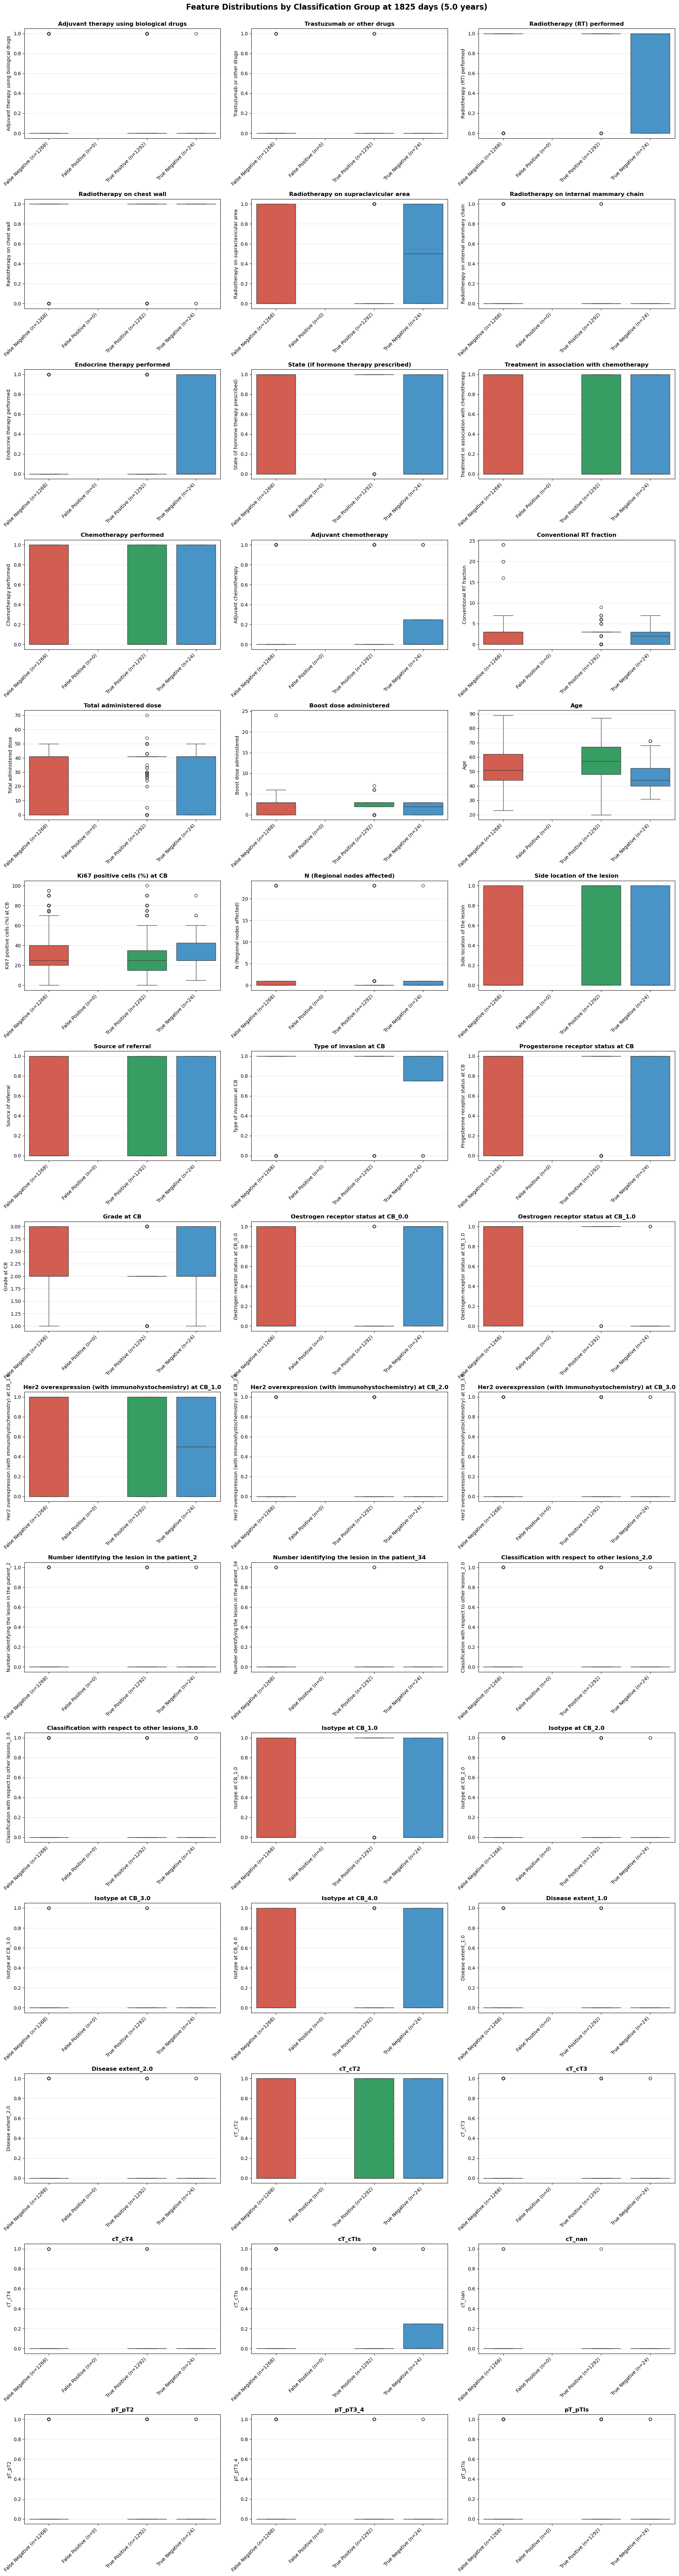


Visualization saved as 'misclassification_feature_comparison_1825d.png'


In [31]:
# Visualize feature distributions for misclassified vs correctly classified
import seaborn as sns

# Select time point for visualization
viz_time = 1825  # 5 years

# Prepare data for visualization
fn_viz = misclass_patients[viz_time]['FN'][continuous_features].copy()
fn_viz['group'] = 'False Negative (n={})'.format(len(fn_viz))

fp_viz = misclass_patients[viz_time]['FP'][continuous_features].copy()
fp_viz['group'] = 'False Positive (n={})'.format(len(fp_viz))

result = misclass_results[viz_time]
tp_viz = train_data_full.iloc[result['TP_indices']][continuous_features].copy()
tp_viz['group'] = 'True Positive (n={})'.format(len(tp_viz))

tn_viz = train_data_full.iloc[result['TN_indices']][continuous_features].copy()
tn_viz['group'] = 'True Negative (n={})'.format(len(tn_viz))

# Combine all groups
all_groups = pd.concat([fn_viz, fp_viz, tp_viz, tn_viz], ignore_index=True)

# Create box plots for each continuous feature
n_features = len(continuous_features)
n_cols = 3
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten() if n_features > 1 else [axes]

colors = ['#e74c3c', '#f39c12', '#27ae60', '#3498db']  # Red, Orange, Green, Blue
group_order = [
    f'False Negative (n={len(fn_viz)})',
    f'False Positive (n={len(fp_viz)})',
    f'True Positive (n={len(tp_viz)})',
    f'True Negative (n={len(tn_viz)})'
]

for idx, feature in enumerate(continuous_features):
    ax = axes[idx]
    
    # Create box plot
    sns.boxplot(data=all_groups, x='group', y=feature, ax=ax, 
                order=group_order, palette=colors)
    
    ax.set_title(f'{feature}', fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(feature, fontsize=10)
    ax.tick_params(axis='x', rotation=45)
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    ax.grid(axis='y', alpha=0.3)

# Remove empty subplots
for idx in range(n_features, len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle(f'Feature Distributions by Classification Group at {viz_time} days ({viz_time/365:.1f} years)', 
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(f'misclassification_feature_comparison_{viz_time}d.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nVisualization saved as 'misclassification_feature_comparison_{viz_time}d.png'")

In [32]:
# Save misclassified patients to CSV for detailed examination
for t in time_points:
    years = t / 365
    
    # Save combined misclassifications
    combined_df = misclass_patients[t]['combined']
    filename = f'misclassified_patients_{int(t)}d_{years:.0f}y.csv'
    combined_df.to_csv(filename, index=False)
    print(f"Saved: {filename} (n={len(combined_df)}: {len(misclass_patients[t]['FN'])} FN, {len(misclass_patients[t]['FP'])} FP)")

print("\n✓ All misclassified patient data saved to CSV files")

Saved: misclassified_patients_365d_1y.csv (n=1289: 1289 FN, 0 FP)
Saved: misclassified_patients_730d_2y.csv (n=1283: 1283 FN, 0 FP)
Saved: misclassified_patients_1095d_3y.csv (n=1279: 1279 FN, 0 FP)
Saved: misclassified_patients_1460d_4y.csv (n=1273: 1273 FN, 0 FP)
Saved: misclassified_patients_1825d_5y.csv (n=1268: 1268 FN, 0 FP)

✓ All misclassified patient data saved to CSV files


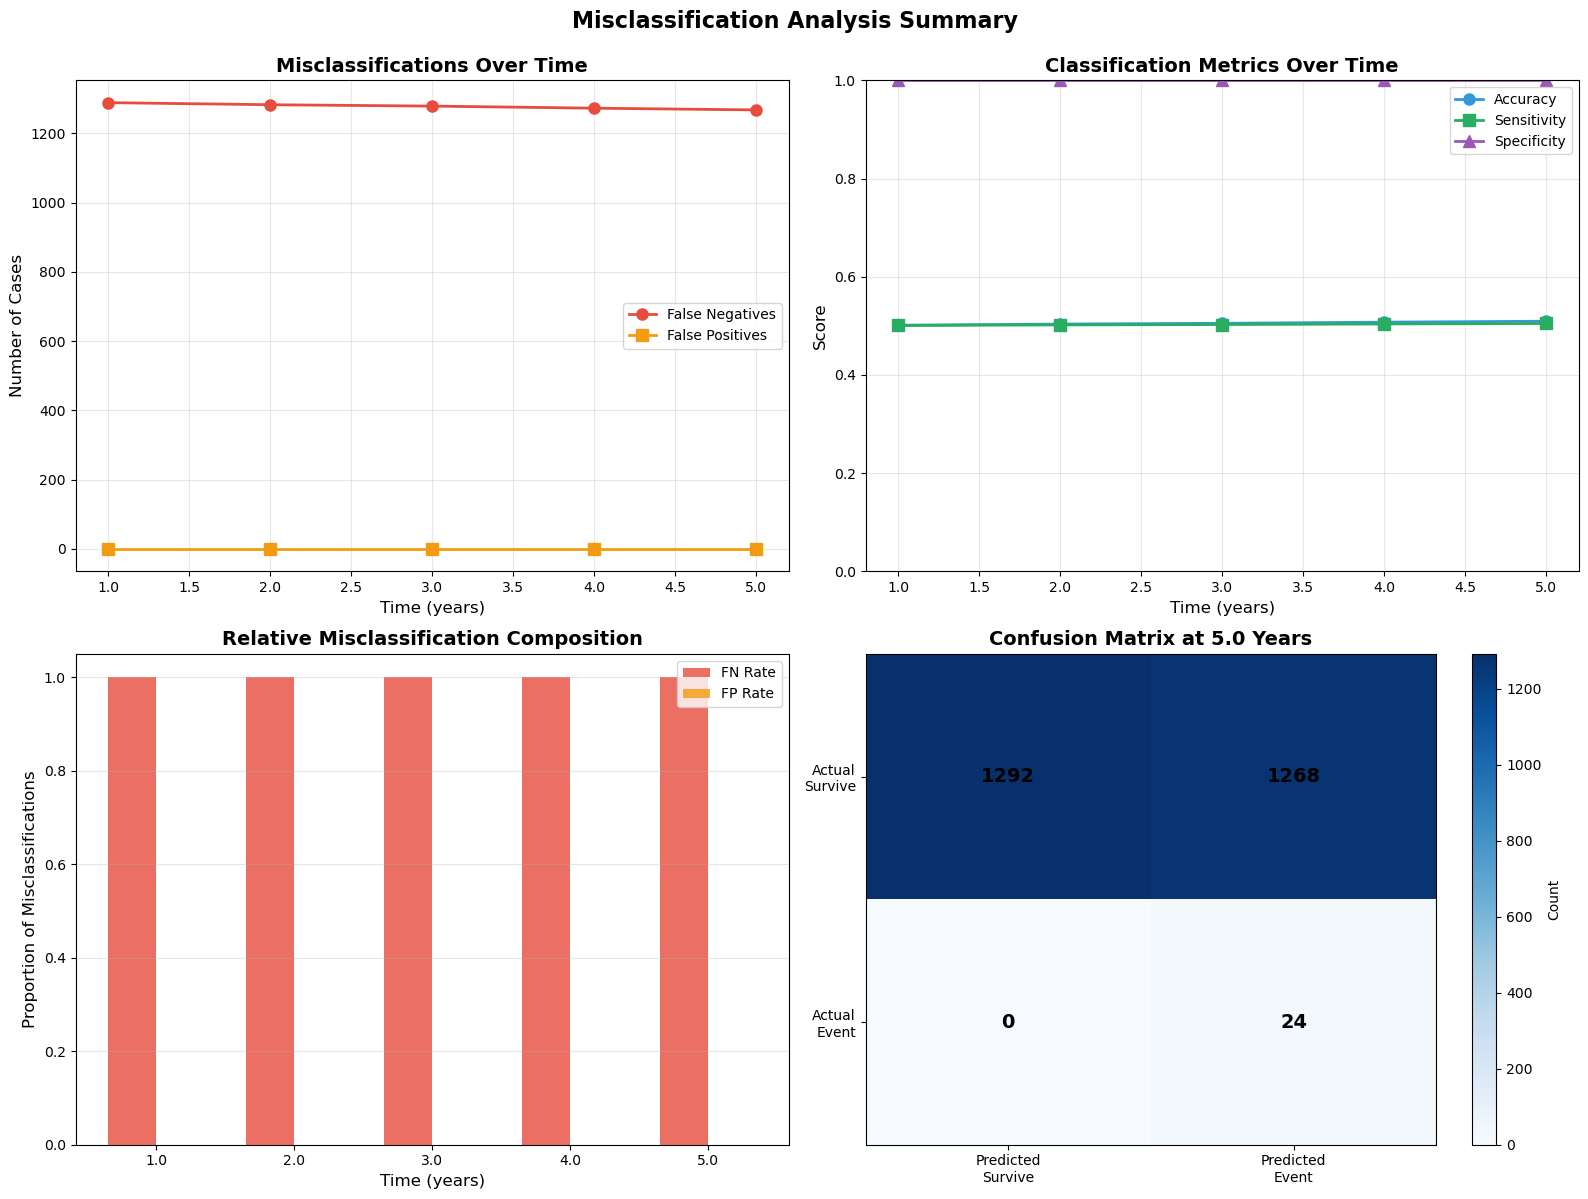


✓ Summary visualization saved as 'misclassification_summary.png'


In [33]:
# Visualize misclassification trends across time points
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Number of misclassifications over time
ax1 = axes[0, 0]
time_years = [t/365 for t in time_points]
n_fn = [misclass_results[t]['n_FN'] for t in time_points]
n_fp = [misclass_results[t]['n_FP'] for t in time_points]

ax1.plot(time_years, n_fn, marker='o', linewidth=2, markersize=8, label='False Negatives', color='#e74c3c')
ax1.plot(time_years, n_fp, marker='s', linewidth=2, markersize=8, label='False Positives', color='#f39c12')
ax1.set_xlabel('Time (years)', fontsize=12)
ax1.set_ylabel('Number of Cases', fontsize=12)
ax1.set_title('Misclassifications Over Time', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Plot 2: Classification metrics over time
ax2 = axes[0, 1]
accuracy = [misclass_results[t]['accuracy'] for t in time_points]
sensitivity = [misclass_results[t]['sensitivity'] for t in time_points]
specificity = [misclass_results[t]['specificity'] for t in time_points]

ax2.plot(time_years, accuracy, marker='o', linewidth=2, markersize=8, label='Accuracy', color='#3498db')
ax2.plot(time_years, sensitivity, marker='s', linewidth=2, markersize=8, label='Sensitivity', color='#27ae60')
ax2.plot(time_years, specificity, marker='^', linewidth=2, markersize=8, label='Specificity', color='#9b59b6')
ax2.set_xlabel('Time (years)', fontsize=12)
ax2.set_ylabel('Score', fontsize=12)
ax2.set_title('Classification Metrics Over Time', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10)
ax2.set_ylim([0, 1])
ax2.grid(True, alpha=0.3)

# Plot 3: Relative misclassification rates
ax3 = axes[1, 0]
total_misclass = [misclass_results[t]['n_FN'] + misclass_results[t]['n_FP'] for t in time_points]
fn_rate = [misclass_results[t]['n_FN'] / total if total > 0 else 0 for t, total in zip(time_points, total_misclass)]
fp_rate = [misclass_results[t]['n_FP'] / total if total > 0 else 0 for t, total in zip(time_points, total_misclass)]

x = np.arange(len(time_years))
width = 0.35

bars1 = ax3.bar(x - width/2, fn_rate, width, label='FN Rate', color='#e74c3c', alpha=0.8)
bars2 = ax3.bar(x + width/2, fp_rate, width, label='FP Rate', color='#f39c12', alpha=0.8)

ax3.set_xlabel('Time (years)', fontsize=12)
ax3.set_ylabel('Proportion of Misclassifications', fontsize=12)
ax3.set_title('Relative Misclassification Composition', fontsize=14, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels([f'{y:.1f}' for y in time_years])
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.3)

# Plot 4: Confusion matrix heatmap for a specific time point
ax4 = axes[1, 1]
viz_time = 1825  # 5 years
result = misclass_results[viz_time]

confusion_matrix = np.array([
    [result['n_TP'], result['n_FN']],
    [result['n_FP'], result['n_TN']]
])

im = ax4.imshow(confusion_matrix, cmap='Blues', aspect='auto')

# Add text annotations
for i in range(2):
    for j in range(2):
        text = ax4.text(j, i, confusion_matrix[i, j],
                       ha="center", va="center", color="black", fontsize=14, fontweight='bold')

ax4.set_xticks([0, 1])
ax4.set_yticks([0, 1])
ax4.set_xticklabels(['Predicted\nSurvive', 'Predicted\nEvent'], fontsize=10)
ax4.set_yticklabels(['Actual\nSurvive', 'Actual\nEvent'], fontsize=10)
ax4.set_title(f'Confusion Matrix at {viz_time/365:.1f} Years', fontsize=14, fontweight='bold')

# Add colorbar
cbar = plt.colorbar(im, ax=ax4)
cbar.set_label('Count', fontsize=10)

plt.suptitle('Misclassification Analysis Summary', fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('misclassification_summary.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Summary visualization saved as 'misclassification_summary.png'")

In [34]:
# Display sample misclassified patients for detailed inspection
inspect_time = 1825  # 5 years

print(f"\n{'=' * 80}")
print(f"SAMPLE MISCLASSIFIED PATIENTS AT {inspect_time} DAYS ({inspect_time/365:.1f} YEARS)")
print(f"{'=' * 80}\n")

# Show a few false negatives
print("--- FALSE NEGATIVES (Predicted event, actually survived) ---")
fn_sample = misclass_patients[inspect_time]['FN'].head(5)
print(f"\nShowing first 5 of {len(misclass_patients[inspect_time]['FN'])} false negatives:")
print(fn_sample[['Survival days', 'Regional LN recurrence', 'predicted_surv_prob'] + continuous_features].to_string())

print("\n\n--- FALSE POSITIVES (Predicted survive, had event) ---")
fp_sample = misclass_patients[inspect_time]['FP'].head(5)
print(f"\nShowing first 5 of {len(misclass_patients[inspect_time]['FP'])} false positives:")
print(fp_sample[['Survival days', 'Regional LN recurrence', 'predicted_surv_prob'] + continuous_features].to_string())

print(f"\n{'=' * 80}")


SAMPLE MISCLASSIFIED PATIENTS AT 1825 DAYS (5.0 YEARS)

--- FALSE NEGATIVES (Predicted event, actually survived) ---

Showing first 5 of 1268 false negatives:
    Survival days  Regional LN recurrence  predicted_surv_prob  Adjuvant therapy using biological drugs  Trastuzumab or other drugs  Radiotherapy (RT) performed  Radiotherapy on chest wall  Radiotherapy on supraclavicular area  Radiotherapy on internal mammary chain  Endocrine therapy performed  State (if hormone therapy prescribed)  Treatment in association with chemotherapy  Chemotherapy performed  Adjuvant chemotherapy  Conventional RT fraction  Total administered dose  Boost dose administered   Age  Ki67 positive cells (%) at CB  N (Regional nodes affected)  Side location of the lesion  Source of referral  Type of invasion at CB  Progesterone receptor status at CB  Grade at CB  Oestrogen receptor status at CB_0.0  Oestrogen receptor status at CB_1.0  Her2 overexpression (with immunohystochemistry) at CB_1.0  Her2 overexpress

In [35]:
# Statistical comparison of features between correctly and incorrectly classified patients
from scipy import stats

analysis_time = 1825  # 5 years

print(f"\n{'=' * 80}")
print(f"STATISTICAL COMPARISON AT {analysis_time} DAYS ({analysis_time/365:.1f} YEARS)")
print(f"{'=' * 80}\n")

result = misclass_results[analysis_time]

# Get all groups
fn_df = misclass_patients[analysis_time]['FN']
fp_df = misclass_patients[analysis_time]['FP']
tp_df = train_data_full.iloc[result['TP_indices']]
tn_df = train_data_full.iloc[result['TN_indices']]

# Combine correct vs incorrect classifications
correct_df = pd.concat([tp_df, tn_df], ignore_index=True)
incorrect_df = pd.concat([fn_df, fp_df], ignore_index=True)

print("\n--- T-Test: Correctly vs Incorrectly Classified ---")
print("(Testing if features differ between correct and incorrect predictions)\n")

comparison_results = []

for feature in continuous_features:
    if feature in train_data_full.columns:
        correct_vals = correct_df[feature].dropna()
        incorrect_vals = incorrect_df[feature].dropna()
        
        if len(correct_vals) > 0 and len(incorrect_vals) > 0:
            t_stat, p_val = stats.ttest_ind(correct_vals, incorrect_vals)
            
            comparison_results.append({
                'Feature': feature,
                'Correct_Mean': correct_vals.mean(),
                'Incorrect_Mean': incorrect_vals.mean(),
                'Difference': incorrect_vals.mean() - correct_vals.mean(),
                'T_Statistic': t_stat,
                'P_Value': p_val,
                'Significant': '***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else ''
            })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values('P_Value')

print(comparison_df.to_string(index=False))
print("\nSignificance: * p<0.05, ** p<0.01, *** p<0.001")

# Save to CSV
comparison_df.to_csv(f'feature_comparison_correct_vs_incorrect_{analysis_time}d.csv', index=False)
print(f"\n✓ Statistical comparison saved to 'feature_comparison_correct_vs_incorrect_{analysis_time}d.csv'")


STATISTICAL COMPARISON AT 1825 DAYS (5.0 YEARS)


--- T-Test: Correctly vs Incorrectly Classified ---
(Testing if features differ between correct and incorrect predictions)

                                                  Feature  Correct_Mean  Incorrect_Mean  Difference  T_Statistic       P_Value Significant
                                        Isotype at CB_1.0      0.842705        0.457413   -0.385292    22.495343 1.748195e-102         ***
                      Oestrogen receptor status at CB_1.0      0.971125        0.658517   -0.312607    22.493814 1.799307e-102         ***
                      Oestrogen receptor status at CB_0.0      0.019757        0.261041    0.241284   -18.958355  3.799360e-75         ***
                    State (if hormone therapy prescribed)      0.918693        0.675868   -0.242826    16.168608  4.350232e-56         ***
                     Radiotherapy on supraclavicular area      0.155015        0.381703    0.226688   -13.478658  4.577636e-40    

In [36]:
# Quick access to misclassified indices for further analysis
print("\n" + "=" * 80)
print("QUICK REFERENCE: Misclassified Patient Indices")
print("=" * 80)

for t in time_points:
    years = t / 365
    result = misclass_results[t]
    
    print(f"\n{t} days ({years:.1f} years):")
    print(f"  False Negative indices (n={len(result['FN_indices'])}): {result['FN_indices'][:10]}{'...' if len(result['FN_indices']) > 10 else ''}")
    print(f"  False Positive indices (n={len(result['FP_indices'])}): {result['FP_indices'][:10]}{'...' if len(result['FP_indices']) > 10 else ''}")

print("\n" + "=" * 80)
print("SUMMARY OF AVAILABLE DATA")
print("=" * 80)
print(f"\n1. misclass_results: Dictionary with detailed results for each time point")
print(f"   Keys: {list(misclass_results.keys())}")
print(f"   Access example: misclass_results[1825]['FN_indices']")

print(f"\n2. misclass_patients: Dictionary with full patient data for misclassified cases")
print(f"   Keys for each time point: 'FN', 'FP', 'combined'")
print(f"   Access example: misclass_patients[1825]['FN']")

print(f"\n3. CSV files saved:")
print(f"   - misclassified_patients_*d_*y.csv (one per time point)")
print(f"   - feature_comparison_correct_vs_incorrect_{analysis_time}d.csv")

print(f"\n4. Visualizations saved:")
print(f"   - misclassification_summary.png")
print(f"   - misclassification_feature_comparison_{viz_time}d.png")

print("\n" + "=" * 80)


QUICK REFERENCE: Misclassified Patient Indices

365 days (1.0 years):
  False Negative indices (n=1289): [ 32  35  36  44  75  87 140 150 161 164]...
  False Positive indices (n=0): []

730 days (2.0 years):
  False Negative indices (n=1283): [ 32  35  36  44  69  75  87 140 150 161]...
  False Positive indices (n=0): []

1095 days (3.0 years):
  False Negative indices (n=1279): [ 32  35  36  44  69  75  87 140 150 161]...
  False Positive indices (n=0): []

1460 days (4.0 years):
  False Negative indices (n=1273): [ 32  35  36  44  75  87 140 150 161 164]...
  False Positive indices (n=0): []

1825 days (5.0 years):
  False Negative indices (n=1268): [ 32  35  36  44  75  87 140 150 161 164]...
  False Positive indices (n=0): []

SUMMARY OF AVAILABLE DATA

1. misclass_results: Dictionary with detailed results for each time point
   Keys: [365, 730, 1095, 1460, 1825]
   Access example: misclass_results[1825]['FN_indices']

2. misclass_patients: Dictionary with full patient data for mi